# Week 7 — NLP in Pharma Commercial: Adverse Events, Field Notes and Social Listening
**Applied Data Science and AI in Pharma Commercial · Columbia DSI · Fall 2026 · Monday, October 26**

Tonight's anchor use case is **adverse-event (AE) detection in free text** — the one NLP problem in pharma commercial where a missed positive is a regulatory failure, not just a lost insight. We build the detector three ways (lexicon → TF-IDF + logistic regression → an optional transformer), choose a threshold with the reviewer's workload in mind, and then open the model up: coefficients, exact word contributions, a hand-rolled LIME, and SHAP. The second half reuses the same toolbox for what the field hears (topics, sentiment, competitor mentions), social listening, medical-information routing, signal detection and semantic search.

**All data are synthetic.** GLUCOREN (Aspen Therapeutics) and CARDIVEX are fictional. The "course PTs" in `ae_lexicon.csv` are plain-English event names, not MedDRA terms (MedDRA is a licensed terminology).

| § | What | Data |
|---|---|---|
| 1 | The text we have | three streams |
| 2 | What the detector must output (the regulatory frame) | `ae_lexicon.csv` |
| 3 | Detector 1: lexicon | field notes (reviewed subset) |
| 4 | Detector 2: TF-IDF + logistic regression; the threshold decision | field notes |
| 5 | Interpretability: coefficients, word contributions, LIME by hand, SHAP, sanity checks | field notes |
| 6 | From detection to intake: four criteria, seriousness, the 15-day clock, the queue | field notes |
| 7 | What the field hears: topics, sentiment, competitor mentions | field notes |
| 8 | Social listening: domain shift | forum posts |
| 9 | Medical-information routing | MI inquiries |
| 10 | Signal detection: PRR / ROR | FAERS-style counts |
| 11 | Semantic search (LSA as a stand-in for embeddings) | field notes |
| 12 | Where GenAI fits — a preview | — |

In [1]:
import pandas as pd, numpy as np, re, warnings, json
import matplotlib.pyplot as plt
from pathlib import Path
warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 160); pd.set_option("display.width", 160)
NAVY, CORAL, ICE, GREY, TEAL = "#1E2761", "#FF6B6B", "#CADCFC", "#888888", "#2A9D8F"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

# ---- locate data/ (the notebook sits in the week folder) and the optional instructor folder
HERE = Path.cwd()
DATA = next(p for p in [HERE / "data", HERE.parent / "data", Path("data")] if (p / "glucoren_field_notes.csv").exists())
INSTR_CANDIDATES = [HERE / "instructor material", HERE.parent / "Instructor material" / "instructor material_w7", HERE / "../Instructor material/instructor material_w7"]
INSTR = next((p for p in INSTR_CANDIDATES if (p / "_INSTRUCTOR_field_notes_truth.csv").exists()), None)
IMG = (INSTR / "build" / "img") if INSTR else (HERE / "figures"); IMG.mkdir(parents=True, exist_ok=True)
def save(name): plt.tight_layout(); plt.savefig(IMG / f"{name}.png", bbox_inches="tight"); plt.show()
print("data folder:", DATA.name + "/", "·", "instructor truth files:", "found" if INSTR else "not present (student mode)", "·", "figures →", "/".join(IMG.parts[-3:]) + "/")

data folder: data/ · instructor truth files: found · figures → instructor material_w7/build/img/


## 1. The text we have

Three streams of unstructured text reach a brand team every week. None of them was written for a model.

* **Field-force call notes** (CRM): what a rep typed after an HCP visit. Short, abbreviated, inconsistent — and, legally, *company knowledge*.
* **Patient-forum posts**: a company-sponsored community and an independent forum. Lay language, first person, emotional.
* **Medical-information (MI) inquiries**: contact-center transcripts and web forms from HCPs, pharmacists and patients.

IQVIA's medical-affairs paper estimates that "approximately 80% of Electronic Medical Record (EMR) data exists in unstructured formats such as clinical notes, scanned documents, and free-text entries" — the same is true of a commercial organization's own data.

In [2]:
notes = pd.read_csv(DATA / "glucoren_field_notes.csv", parse_dates=["call_date"])
posts = pd.read_csv(DATA / "patient_forum_posts.csv", parse_dates=["post_date"])
mi    = pd.read_csv(DATA / "medinfo_inquiries.csv", parse_dates=["inquiry_date"])
lex   = pd.read_csv(DATA / "ae_lexicon.csv")
print(f"field notes {len(notes):,} · forum posts {len(posts):,} · MI inquiries {len(mi):,} · lexicon {len(lex)} lay terms → {lex.course_pt.nunique()} course PTs")
print(f"reviewed by PV: notes {notes.pv_reviewed.sum():,} ({notes.pv_reviewed.mean():.0%}), posts {posts.pv_reviewed.sum():,}, MI labelled {mi.mi_team_intent.notna().sum():,}")
notes.sample(6, random_state=7)[["call_date", "specialty", "region", "note_text"]]

field notes 4,200 · forum posts 3,000 · MI inquiries 1,200 · lexicon 77 lay terms → 29 course PTs
reviewed by PV: notes 1,458 (35%), posts 741, MI labelled 585


,call_date,specialty,region,note_text
1748,2026-04-09,PCP,South,HCP seeing A1c reductions of about 0.6 points in patients added to metformin. Very satisfied with GLUCOREN so far. Will follow up next month.
3098,2026-05-08,Endocrinology,South,"A 71-year-old female patient went to the ER with throat closing within two weeks of starting. HCP suspects GLUCOREN, has stopped it, and wants a medical inf..."
444,2025-12-06,PCP,Midwest,HCP has started several patients on CARDIVEX since the cardiovascular outcomes label update. Sees GLUCOREN as second choice now. Will follow up next month.
2898,2025-12-11,PCP,West,Shared the elderly sub-group analysis. HCP found the efficacy consistent and wants the reprint. Next call: bring the renal sub-group data.
1121,2026-08-01,PCP,South,Discussed combination with basal insulin and whether to reduce the insulin dose. Referred to Medical Information for patient-specific advice. Left the updat...
449,2026-03-15,NP/PA,Northeast,Patients on Cigna Medicare plan hitting the coverage gap; HCP asked what assistance exists. Shared patient assistance program details. Next call: bring the ...


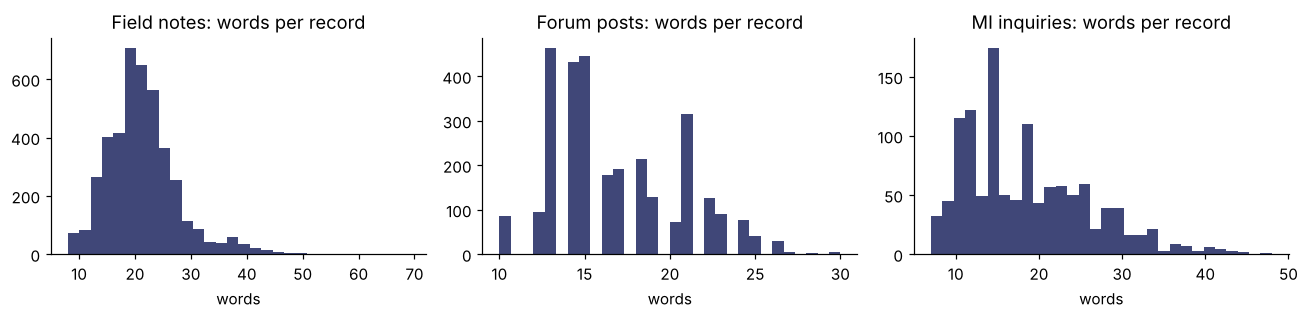

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3))
for a, (df, col, ttl) in zip(ax, [(notes, "note_text", "Field notes"), (posts, "text", "Forum posts"), (mi, "text", "MI inquiries")]):
    a.hist(df[col].str.split().str.len(), bins=30, color=NAVY, alpha=.85); a.set_title(f"{ttl}: words per record"); a.set_xlabel("words")
save("text_lengths")

## 2. What the detector must output — the regulatory frame

An AE classifier is not a sentiment model. Its output feeds a *reporting obligation*, so we define the target in the regulator's terms before we fit anything.

* **Adverse experience** — "any adverse event associated with the use of a drug in humans, whether or not considered drug related" (21 CFR 314.80(a)).
* **The four elements** that make a case reportable (FDA draft guidance, Postmarketing Safety Reporting, 2001, §IV.B): an **identifiable patient**, an **identifiable reporter**, a **suspect drug**, and an **adverse experience**.
* **Serious** — death, life-threatening, hospitalization (initial or prolonged), disability, congenital anomaly, or other medically important event (21 CFR 314.80(a)).
* **Unexpected** — not in the current label. **Serious and unexpected → 15-day Alert report** (21 CFR 314.80(c)(1)). Everything else goes in periodic reports.
* **Company knowledge** — FDA "will consider an applicant responsible for information known to its employees, affiliates, and contractors" (2001 guidance, §X). A rep's call note is company knowledge from the moment it is saved.

So the pipeline must answer four questions per record, in order: *AE mentioned? → four elements present? → serious? → expected?* — and compute a due date.

In [4]:
lex["in_label"] = lex.in_label.replace({"-": "n/a"})
print(lex.groupby(["in_label", "serious_default"]).course_pt.nunique().rename("course PTs"))
lex.query("in_label == 'N'").drop_duplicates("course_pt")[["course_pt", "lay_term", "serious_default"]].head(12)

in_label  serious_default
N         N                   1
          Y                   8
Y         N                  17
n/a       Y                   3
Name: course PTs, dtype: int64


,course_pt,lay_term,serious_default
49,Pancreatitis,pancreatitis,Y
52,Acute kidney injury,kidney injury,Y
56,Hepatic enzyme increased,liver enzymes,Y
57,Hepatic injury,jaundice,Y
59,Angioedema,swelling of the face,Y
62,Anaphylactic reaction,anaphylaxis,Y
63,Syncope,passed out,Y
66,Chest pain,chest pain,Y
67,Palpitations,heart racing,N


## 3. Detector 1 — a lexicon

The simplest detector: flag a note if any lay term in the lexicon appears. We evaluate against the PV reviewer's labels on the 30% of notes they have read. Watch where it fails.

In [5]:
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, precision_recall_curve, average_precision_score, roc_auc_score
LAY_TERMS = sorted(lex.lay_term.unique(), key=len, reverse=True)
LAY_RE = re.compile(r"\b(" + "|".join(re.escape(t) for t in LAY_TERMS) + r")\b", re.I)
def lexicon_flag(s): return int(bool(LAY_RE.search(str(s))))
notes["lex_flag"] = notes.note_text.map(lexicon_flag)
rev = notes[notes.pv_reviewed == 1].copy(); y = rev.pv_label_ae.astype(int)
def report(y_true, y_pred, name):
    p, r, f = precision_score(y_true, y_pred), recall_score(y_true, y_pred), f1_score(y_true, y_pred)
    print(f"{name:<34} precision {p:.2f}  recall {r:.2f}  F1 {f:.2f}  flagged {int(np.sum(y_pred)):>4} of {len(y_pred)}")
    return p, r, f
_ = report(y, rev.lex_flag, "Lexicon (any lay term)")
pd.DataFrame(confusion_matrix(y, rev.lex_flag), index=["reviewer: no AE", "reviewer: AE"], columns=["flag 0", "flag 1"])

Lexicon (any lay term)             precision 0.42  recall 0.79  F1 0.55  flagged  270 of 1458


,flag 0,flag 1
reviewer: no AE,1157,156
reviewer: AE,31,114


In [6]:
# where the lexicon is wrong
fp = rev[(rev.lex_flag == 1) & (y == 0)]; fn = rev[(rev.lex_flag == 0) & (y == 1)]
print(f"FALSE POSITIVES ({len(fp)}): the word is there, the event is not —")
for t in fp.note_text.head(4): print("  •", t)
print(f"\nFALSE NEGATIVES ({len(fn)}): the event is there, the word is not —")
for t in fn.note_text.head(4): print("  •", t)

FALSE POSITIVES (156): the word is there, the event is not —
  • Checked in on tolerability: nothing reported, no yeast infection, no discontinuations.
  • HCP compared GLUCOREN with CARDIVEX on A1c; sees them as similar and chooses on access. HCP mentioned using GLUCOREN for weight loss in a non-diabetic patient. Did not engage; documented and referred to MI. Good 10-minute conversation.
  • HCP not convinced the cardiovascular data are differentiated. Wants to see outcomes, not surrogate markers. HCP mentioned using GLUCOREN for weight loss in a non-diabetic pt. Did not engage; documented and referred to MI. Good 10-minute conversation.
  • HCP reporst no side effects to speak of — specifically no headache. Will keep starting new pts. HCP sees roughly 26 T2D pts a week.

FALSE NEGATIVES (31): the event is there, the word is not —
  • Call from the office: one of her patients a couple of lows, is this known? Gave the MI number and reminded them to report. Office staff friendly as alwa

Two failure families, and they are the whole story of why we move past rules:

1. **Negation and general statements** — "no reports of nausea", "asked about the nausea rate in the label". The word is present; no patient had anything. A lexicon has no notion of *who* and *whether*.
2. **Paraphrase, typos, abbreviations** — "N/V", "GI issues", "dropped off due to stomach upset", "nuasea". The event is there; the string is not.

A model that learns from reviewer labels can pick up the context words ("developed", "stopped because of", "one of his patients") and the negation words ("no", "denied") that a lexicon ignores.

## 4. Detector 2 — TF-IDF + logistic regression

Bag-of-words with 1–2-grams, TF-IDF weighting, L2-regularized logistic regression — plus one classic trick, **negation scope marking**: the few words after "no", "denied" or "without" get a `NOT_` prefix, so "no nausea" and "nausea" are different features. Deliberately simple: it trains in a second, it is linear (so §5 can explain it exactly), and on short notes it is hard to beat by much. We cross-validate on the reviewed notes and look at the **precision–recall curve** — in safety work the operating point matters more than any single score.

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_predict
NEG_WORDS = {"no", "not", "denied", "denies", "without", "never", "none", "nothing"}
def normalize(s):
    #   lower-case, expand rep shorthand, and mark negation scope: the three words after a negation cue get a NOT_ prefix
    #   (Das & Chen 2001; Pang, Lee & Vaithyanathan 2002) so that 'no nausea' and 'nausea' become different features.
    s = str(s).lower()
    s = re.sub(r"\bn/v\b", "nausea vomiting", s); s = re.sub(r"\bpts?\b", "patient", s); s = re.sub(r"\bw/o\b", "without", s); s = re.sub(r"\bw/\b", "with", s)
    out, scope = [], 0
    for w in s.split():
        core = re.sub(r"[^a-z0-9/]", "", w)
        if core in NEG_WORDS: scope = 3; out.append(w); continue
        if scope and core: out.append("NOT_" + w); scope -= 1
        else: out.append(w)
        if w.endswith((".", ";", ",")): scope = 0
    return " ".join(out)
pipe = make_pipeline(TfidfVectorizer(preprocessor=normalize, ngram_range=(1, 2), min_df=2, sublinear_tf=True), LogisticRegression(C=4.0, max_iter=2000, class_weight="balanced"))
cv = StratifiedKFold(5, shuffle=True, random_state=7)
proba_cv = cross_val_predict(pipe, rev.note_text, y, cv=cv, method="predict_proba")[:, 1]
print(f"5-fold CV · ROC-AUC {roc_auc_score(y, proba_cv):.3f} · average precision {average_precision_score(y, proba_cv):.3f}")
_ = report(y, (proba_cv >= 0.5).astype(int), "LR @ threshold 0.50")
_ = report(y, rev.lex_flag, "Lexicon (for comparison)")

5-fold CV · ROC-AUC 0.987 · average precision 0.936
LR @ threshold 0.50                precision 0.94  recall 0.93  F1 0.94  flagged  143 of 1458
Lexicon (for comparison)           precision 0.42  recall 0.79  F1 0.55  flagged  270 of 1458


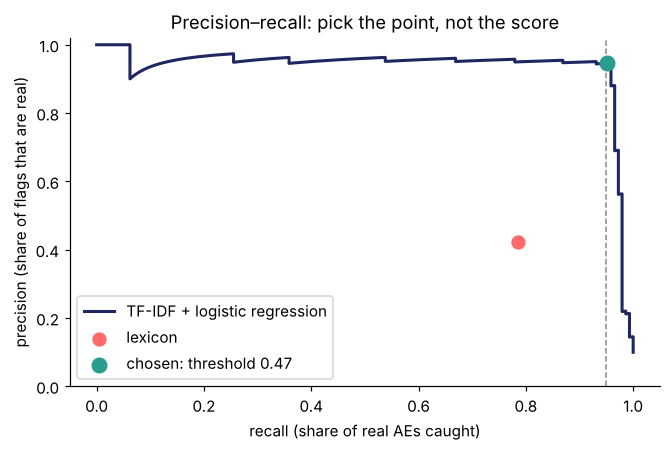

LR @ threshold 0.47 (recall ≥ 0.95) precision 0.95  recall 0.95  F1 0.95  flagged  146 of 1458


In [8]:
prec, recl, thr = precision_recall_curve(y, proba_cv)
# the operating point: the lowest threshold that still gives recall >= 0.95 (a missed AE is a compliance failure)
TARGET_RECALL = 0.95
ok = np.where(recl[:-1] >= TARGET_RECALL)[0]; i_star = ok[np.argmax(prec[:-1][ok])]; T_STAR = float(thr[i_star])
fig, ax = plt.subplots(figsize=(6.2, 4.2))
ax.plot(recl, prec, color=NAVY, lw=2, label="TF-IDF + logistic regression")
ax.scatter([recall_score(y, rev.lex_flag)], [precision_score(y, rev.lex_flag)], color=CORAL, s=70, zorder=5, label="lexicon")
ax.scatter([recl[i_star]], [prec[i_star]], color=TEAL, s=90, zorder=6, label=f"chosen: threshold {T_STAR:.2f}")
ax.axvline(TARGET_RECALL, color=GREY, ls="--", lw=1); ax.set_xlabel("recall (share of real AEs caught)"); ax.set_ylabel("precision (share of flags that are real)")
ax.set_title("Precision–recall: pick the point, not the score"); ax.legend(loc="lower left"); ax.set_ylim(0, 1.02)
save("pr_curve")
flag_star = (proba_cv >= T_STAR).astype(int)
_ = report(y, flag_star, f"LR @ threshold {T_STAR:.2f} (recall ≥ {TARGET_RECALL})")

### The threshold is a business decision, not a statistic

Every flagged note is read by a PV reviewer. Every *missed* AE is an unreported case. Put rough costs on both and the threshold chooses itself:

In [9]:
REVIEW_MIN = 6          # minutes for a trained reviewer to read a note and decide
NOTES_PER_WEEK = len(notes) / 50   # the stream runs ~50 weeks
rows = []
for t in [0.2, 0.3, T_STAR, 0.5, 0.7]:
    f = (proba_cv >= t).astype(int); r = recall_score(y, f); p = precision_score(y, f)
    flagged_per_week = f.mean() * NOTES_PER_WEEK
    rows.append(dict(threshold=round(t, 2), recall=round(r, 3), precision=round(p, 2), flagged_per_week=round(flagged_per_week), reviewer_hours_per_week=round(flagged_per_week * REVIEW_MIN / 60, 1), AEs_missed_per_year=round((1 - r) * y.mean() * len(notes))))
pd.DataFrame(rows)

,threshold,recall,precision,flagged_per_week,reviewer_hours_per_week,AEs_missed_per_year
0,0.20,0.972,0.62,13,1.3,12
1,0.30,0.966,0.80,10,1.0,14
2,0.47,0.952,0.95,8,0.8,20
3,0.50,0.931,0.94,8,0.8,29
4,0.70,0.786,0.95,7,0.7,89


The chosen point costs a few reviewer-hours a week and misses a handful of cases a year; a 0.5 threshold saves an hour and misses several times as many. In a safety setting the answer is almost always "high recall, and a human reads the flags". The same logic — *recall first, workload second* — is what the IQVIA signal-management paper calls the operating model: "A human-in-the-loop model … is not a way station en route to full automation. It is the operating model itself."

In [10]:
# fit the production model on all reviewed notes and score the whole stream
pipe.fit(rev.note_text, y)
notes["p_ae"] = pipe.predict_proba(notes.note_text)[:, 1]; notes["flag_ae"] = (notes.p_ae >= T_STAR).astype(int)
vec, clf = pipe.named_steps["tfidfvectorizer"], pipe.named_steps["logisticregression"]
print(f"vocabulary {len(vec.vocabulary_):,} terms · flagged {notes.flag_ae.sum():,} of {len(notes):,} notes ({notes.flag_ae.mean():.1%})")
if INSTR:   # instructor check against the generator's truth
    truth = pd.read_csv(INSTR / "_INSTRUCTOR_field_notes_truth.csv"); notes_t = notes.merge(truth, on="note_id")
    unrev = notes_t[notes_t.pv_reviewed == 0]
    print(f"[instructor] on the {len(unrev):,} UNREVIEWED notes: recall {recall_score(unrev.ae_present, unrev.flag_ae):.3f} · precision {precision_score(unrev.ae_present, unrev.flag_ae):.2f} · lexicon recall {recall_score(unrev.ae_present, unrev.lex_flag):.3f}")

vocabulary 2,586 terms · flagged 458 of 4,200 notes (10.9%)
[instructor] on the 2,742 UNREVIEWED notes: recall 0.960 · precision 0.94 · lexicon recall 0.789


## 5. Interpretability — opening the model

> "If you cannot explain how your AI came to a decision, it does not belong in a compliance system." — IQVIA, *Expert Predictions for 2026* (safety and PV)

Four questions a PV lead will ask, and the method that answers each:

| Question | Scope | Method tonight | Reference |
|---|---|---|---|
| What does the model think an AE looks like, in general? | global | coefficients of the linear model | Molnar, *Interpretable ML*, ch. 5 |
| Why was *this* note flagged? | local, exact | word contribution = coefficient × TF-IDF weight | (linear models are self-explaining) |
| Why was this note flagged — if the model were a black box? | local, model-agnostic | **LIME**: perturb the text, fit a local linear surrogate | Ribeiro, Singh & Guestrin, KDD 2016 |
| Same, with a consistent accounting of credit | local + global | **SHAP** values | Lundberg & Lee, NeurIPS 2017 |
| For transformers: which tokens mattered? | local | Integrated Gradients; attention — *with care* | Sundararajan et al., ICML 2017; Jain & Wallace, NAACL 2019 |

Rudin (2019) argues that for high-stakes decisions we should prefer models that are interpretable by construction over post-hoc explanations of black boxes. Tonight's detector is exactly that; LIME and SHAP are shown so you can read them when a vendor's model is not.

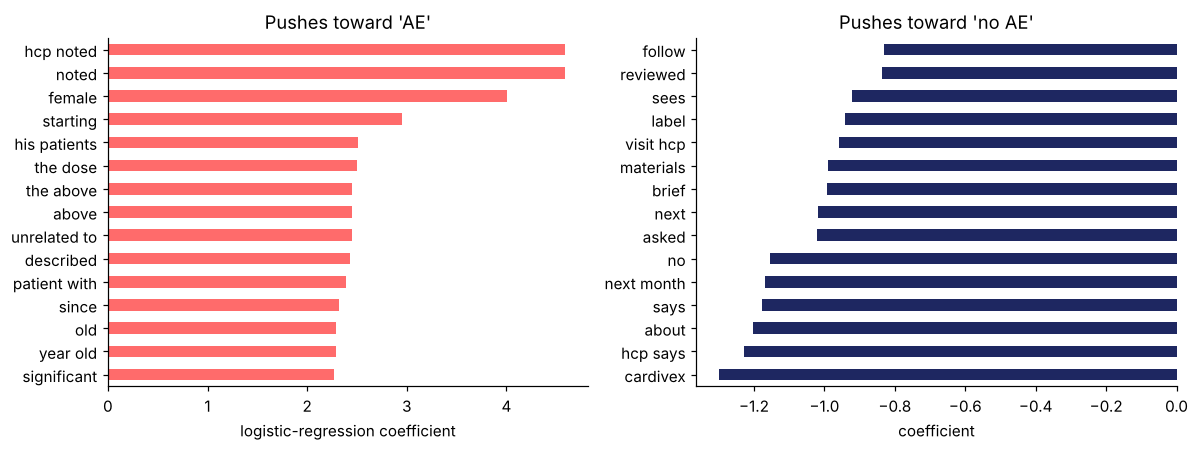

In [11]:
# 5a. GLOBAL — what the model learned
coefs = pd.Series(clf.coef_[0], index=vec.get_feature_names_out()).sort_values()
FUNCTION = set("of it the a an and with had has his her their one in for to on at by is was as that this".split())
content = coefs[[not set(f.split()) <= FUNCTION for f in coefs.index]]        # hide pure function-word features from the chart (they stay in the model)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
content.tail(15).plot.barh(ax=ax[0], color=CORAL); ax[0].set_title("Pushes toward 'AE'"); ax[0].set_xlabel("logistic-regression coefficient")
content.head(15).plot.barh(ax=ax[1], color=NAVY); ax[1].set_title("Pushes toward 'no AE'"); ax[1].set_xlabel("coefficient")
save("coefficients")

Read the two panels as the model's definition of an AE: *event words* ("nausea", "dizziness") plus *case words* ("developed", "stopped", "patient", "hospitalized") on one side; *negation and generality* ("no", "denied", "label", "rate", "asked about") on the other. That is the right thing to have learned. Anything else in these panels — a payer name, a region, a rep's habit of writing "fyi" — would be a shortcut to fix, not a feature to celebrate (§5e checks for exactly that).

In [12]:
# 5b. LOCAL, EXACT — word contributions for one note (linear model: contribution = coefficient × tf-idf weight)
from IPython.display import HTML, display
def contributions(text):
    X = vec.transform([text]); idx = X.nonzero()[1]
    c = pd.Series(X.toarray()[0, idx] * clf.coef_[0][idx], index=vec.get_feature_names_out()[idx]).sort_values()
    return c, float(clf.intercept_[0])
def highlight(text, contrib):
    toks = normalize(text).split(); out = []
    for w in toks:
        key = re.sub(r"[^a-z0-9/]", "", w)
        v = contrib.get(key, 0.0)
        a = min(abs(v) / 1.2, 1.0)
        bg = f"rgba(255,107,107,{a:.2f})" if v > 0 else (f"rgba(30,39,97,{a:.2f})" if v < 0 else "transparent")
        fg = "white" if a > 0.55 else "black"
        out.append(f"<span style='background:{bg};color:{fg};padding:1px 3px;border-radius:3px'>{w}</span>")
    return "<p style='font-family:Calibri,sans-serif;font-size:15px;line-height:1.9'>" + " ".join(out) + "</p>"
examples = pd.concat([notes[notes.flag_ae == 1].sample(2, random_state=3), notes[(notes.flag_ae == 0) & (notes.lex_flag == 1)].sample(2, random_state=3)])
for _, r in examples.iterrows():
    c, b = contributions(r.note_text)
    display(HTML(f"<b>{r.note_id}</b> · p(AE) = {r.p_ae:.2f} · flagged = {r.flag_ae} · lexicon = {r.lex_flag}" + highlight(r.note_text, c)))
    print("  top +:", ", ".join(f"{k} ({v:+.2f})" for k, v in c.tail(3)[::-1].items()), " | top −:", ", ".join(f"{k} ({v:+.2f})" for k, v in c.head(3).items()))

  top +: to report (+0.26), report (+0.26), mrn (+0.19)  | top −: the (-0.07), office (-0.03), call (-0.01)


  top +: of (+0.61), one of (+0.35), glucoren due (+0.30)  | top −: two patient (-0.09), for (-0.07), scripts (-0.06)


  top +: of (+0.51), dose (+0.25), related (+0.16)  | top −: the pi (-0.09), shared (-0.09), section of (-0.08)


  top +: it (+0.59), hives (+0.27), patient (+0.17)  | top −: brief (-0.11), visit hcp (-0.11), trial (-0.10)


Red = pushes toward AE, blue = pushes away. The two bottom examples are lexicon false positives that the model correctly suppressed — and the highlighted words tell the reviewer *why* in one glance ("no", "denied", "rate", "label"). This is the explanation format reviewers actually want: the span, not a number.

In [13]:
# 5c. LIME by hand — treat the model as a black box; perturb the text; fit a local linear surrogate
rng = np.random.default_rng(7)
def lime_by_hand(text, n_samples=400, predict=lambda L: pipe.predict_proba(L)[:, 1]):
    words = text.split(); W = len(words)
    masks = rng.random((n_samples, W)) > 0.5; masks[0] = True              # 1 = keep the word
    variants = [" ".join(w for w, m in zip(words, row) if m) or " " for row in masks]
    p = predict(variants)
    # kernel weights: variants closer to the original count more (cosine distance on the mask)
    dist = 1 - masks.sum(1) / W; weights = np.exp(-(dist ** 2) / 0.25 ** 2)
    from sklearn.linear_model import Ridge
    surrogate = Ridge(alpha=1.0).fit(masks.astype(float), p, sample_weight=weights)
    return pd.Series(surrogate.coef_, index=words).sort_values(), p[0]
ex = notes[(notes.p_ae > 0.8) & (notes.note_text.str.len() < 160)].sample(1, random_state=11).iloc[0]
lime, p0 = lime_by_hand(ex.note_text)
print(ex.note_text, f"\n→ p(AE) = {p0:.2f}\n")
print("LIME surrogate weights (word → effect on p when kept):")
print(pd.concat([lime.tail(5)[::-1], lime.head(4)]).round(3).to_string())

A 49 y/o m — constipated. Dose held, HCP to reassess. 
→ p(AE) = 0.95

LIME surrogate weights (word → effect on p when kept):
held,        0.132
reassess.    0.097
Dose         0.095
to           0.063
HCP          0.046
49          -0.056
y/o         -0.013
—           -0.006
m            0.004


That is the entire LIME idea in fifteen lines: **sample neighbours** of the input (words switched off), **ask the black box** for its predictions, **weight neighbours by closeness**, **fit a small linear model** and read its weights. The surrogate agrees with the exact contributions above because our model *is* linear — the value of LIME is that the same recipe works when it is not. Two cautions from the literature: explanations are local and can be unstable under re-sampling (change the seed and compare), and perturbed text ("stopped because of") is sometimes off the data manifold, so the black box is being asked about sentences nobody writes.

Background dataset has 1458 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=1458 when initializing the masker.


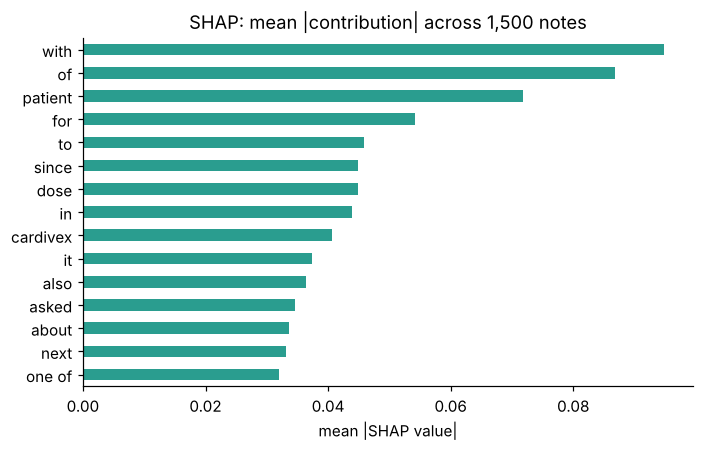

Top-15 SHAP features that are also top-15 |coefficients|: 4 of 15 — SHAP weights by how often a term occurs, coefficients do not


In [14]:
# 5d. SHAP — the same question with a consistent accounting of credit (Shapley values); falls back gracefully if shap is not installed
try:
    import shap
    X_rev = vec.transform(rev.note_text)
    explainer = shap.LinearExplainer(clf, X_rev, feature_perturbation="interventional")
    sv = explainer.shap_values(vec.transform(notes.note_text.iloc[:1500]))
    mean_abs = pd.Series(np.asarray(np.abs(sv).mean(0)).ravel(), index=vec.get_feature_names_out()).sort_values(ascending=False)
    fig, ax = plt.subplots(figsize=(6.5, 4.2)); mean_abs.head(15)[::-1].plot.barh(ax=ax, color=TEAL); ax.set_title("SHAP: mean |contribution| across 1,500 notes"); ax.set_xlabel("mean |SHAP value|")
    save("shap_global")
    print("Top-15 SHAP features that are also top-15 |coefficients|:", len(set(mean_abs.head(15).index) & set(coefs.abs().sort_values().tail(15).index)), "of 15 — SHAP weights by how often a term occurs, coefficients do not")
except Exception as e:
    print("shap not available in this environment —", type(e).__name__, "· pip install shap to run this cell")

In [15]:
# 5e. SANITY CHECKS a PV lead should demand before trusting any detector
# (1) does the model lean on anything that is not language about events?  (2) does a trivial edit flip it?  (3) does it behave on negation?
leak_terms = [t for t in coefs.index if any(k in t.split() for k in ["aetna", "cigna", "bcbs", "humana", "optumrx", "caremark", "midwest", "northeast", "west", "south", "dr."])]
leaks = sorted([(t, round(float(coefs[t]), 2)) for t in leak_terms if abs(coefs[t]) > 0.5], key=lambda x: -abs(x[1]))
print("Payer/region terms with |coef| > 0.5:", leaks[:8] or "none")
print("→ any such term is a shortcut the model found in the training sample, not knowledge about adverse events; drop it from the vocabulary or add notes that break the correlation.")
probe = ["Patient developed nausea after starting GLUCOREN and stopped the drug.",
         "Patient had no nausea after starting GLUCOREN; tolerating well.",
         "HCP asked about the nausea rate in the label; no specific patient discussed.",
         "One of his pts had N/V within 2 wks of starting, dose reduced.",
         "A 61 y/o F was hospitalized with pancreatitis three weeks after starting GLUCOREN."]
for t in probe: print(f"{pipe.predict_proba([t])[0,1]:.2f}  {t}")

Payer/region terms with |coef| > 0.5: [('optumrx moved', 2.05), ('cigna is', 1.75), ('reports cigna', 1.75), ('optumrx', 1.14), ('with aetna', 0.87), ('humana hcp', 0.83), ('bcbs', -0.6), ('humana moved', -0.6)]
→ any such term is a shortcut the model found in the training sample, not knowledge about adverse events; drop it from the vocabulary or add notes that break the correlation.
0.94  Patient developed nausea after starting GLUCOREN and stopped the drug.
0.34  Patient had no nausea after starting GLUCOREN; tolerating well.
0.07  HCP asked about the nausea rate in the label; no specific patient discussed.
0.99  One of his pts had N/V within 2 wks of starting, dose reduced.
0.87  A 61 y/o F was hospitalized with pancreatitis three weeks after starting GLUCOREN.


The probes are a tiny **behavioural test set**: a positive, its negation, a generic statement, an abbreviated paraphrase, and a serious case. Keep a list like this in version control and run it on every retrain — it catches more than a dashboard of aggregate metrics does.

**The remedy for a shortcut is to remove the shortcut**, not to explain it away. Masking entities (payer names → `payer`, names and dates → placeholders) is a two-line change to the normalizer; it also happens to be the first step of PHI handling. Precision and recall barely move, and the leak check comes back clean:

> For transformer models the same questions get harder. Attention weights are tempting as explanations, but Jain & Wallace (2019) showed they often do not identify the inputs the model actually relies on; Integrated Gradients (Sundararajan et al., 2017) is the better-founded choice. The behavioural probes above work for any model.

In [16]:
PAYER_RE = re.compile(r"\b(aetna|unitedhealthcare|cigna|bcbs|humana|medicaid mco|express scripts|cvs caremark|optumrx|caremark|optum)\b", re.I)
def normalize_masked(s): return normalize(PAYER_RE.sub("payer", str(s)))
pipe_m = make_pipeline(TfidfVectorizer(preprocessor=normalize_masked, ngram_range=(1, 2), min_df=2, sublinear_tf=True), LogisticRegression(C=4.0, max_iter=2000, class_weight="balanced"))
pm = cross_val_predict(pipe_m, rev.note_text, y, cv=cv, method="predict_proba")[:, 1]
print(f"masked model · ROC-AUC {roc_auc_score(y, pm):.3f} · average precision {average_precision_score(y, pm):.3f}   (unmasked: {roc_auc_score(y, proba_cv):.3f} / {average_precision_score(y, proba_cv):.3f})")
pipe_m.fit(rev.note_text, y); coefs_m = pd.Series(pipe_m.named_steps["logisticregression"].coef_[0], index=pipe_m.named_steps["tfidfvectorizer"].get_feature_names_out())
print("payer-name features left in the vocabulary:", [t for t in coefs_m.index if PAYER_RE.search(t)] or "none")

masked model · ROC-AUC 0.987 · average precision 0.938   (unmasked: 0.987 / 0.936)
payer-name features left in the vocabulary: none


## 6. From detection to intake — the four elements, seriousness and the clock

A flag is not a case. The reviewer's next questions are rule-shaped, so we encode them as rules on top of the model and *measure* the rules too.

In [17]:
PATIENT_RE = re.compile(r"(\b\d{2}\s*-?\s*(year|yr|y/?o)\b|\bone of (his|her|their) patients?\b|\ba (long-standing )?(patient|pt)\b|\bmrs?\.|\bmrn\b|\bdob\b|\bpatient [A-Z][a-z]+ [A-Z][a-z]+)", re.I)
SERIOUS_TERMS = lex[lex.serious_default == "Y"].lay_term.tolist()
SER_RE = re.compile(r"\b(" + "|".join(re.escape(t) for t in SERIOUS_TERMS) + r")\b", re.I)
UNEXPECTED_TERMS = lex[lex.in_label == "N"].lay_term.tolist()
UNEXP_RE = re.compile(r"\b(" + "|".join(re.escape(t) for t in UNEXPECTED_TERMS) + r")\b", re.I)
PHI_RE = re.compile(r"\b(DOB|MRN)\b|\bMrs?\.\s+[A-Z][a-z]+|\b(patient|pt) [A-Z][a-z]+ [A-Z][a-z]+")   # case-sensitive on purpose: names are capitalized

q = notes[notes.flag_ae == 1].copy()
q["identifiable_patient"] = q.note_text.str.contains(PATIENT_RE).astype(int)
q["identifiable_reporter"] = 1                      # the HCP (via the rep) — always known in CRM
q["suspect_drug"] = q.note_text.str.contains("GLUCOREN|the drug|dose", case=False).astype(int) | 1   # brand context: every call is about GLUCOREN
q["serious_terms"] = q.note_text.str.contains(SER_RE).astype(int)
q["unexpected_terms"] = q.note_text.str.contains(UNEXP_RE).astype(int)
q["valid_case"] = q.identifiable_patient & q.identifiable_reporter & q.suspect_drug
q["expedited_15day"] = (q.valid_case & q.serious_terms & q.unexpected_terms).astype(int)
q["aware_date"] = q.call_date; q["due_date"] = np.where(q.expedited_15day == 1, q.call_date + pd.Timedelta(days=15), pd.NaT)
q["phi_in_note"] = q.note_text.str.contains(PHI_RE).astype(int)
print(f"flagged {len(q):,} → valid cases (4 elements) {q.valid_case.sum():,} → serious terms {q.serious_terms.sum()} → 15-day candidates {q.expedited_15day.sum()} · notes with PHI {q.phi_in_note.sum()}")
q.sort_values(["expedited_15day", "p_ae"], ascending=False)[["note_id", "call_date", "p_ae", "identifiable_patient", "serious_terms", "unexpected_terms", "expedited_15day", "due_date", "note_text"]].head(8)

flagged 458 → valid cases (4 elements) 418 → serious terms 51 → 15-day candidates 50 · notes with PHI 28


,note_id,call_date,p_ae,identifiable_patient,serious_terms,unexpected_terms,expedited_15day,due_date,note_text
2018,N02019,2025-11-19,0.994621,1,1,1,1,2025-12-04,"One of his patients went to the ER with yellow eyes since the dose was increased. HCP suspects GLUCOREN, has stopped it, and wants a medical information fol..."
2174,N02175,2026-01-22,0.993631,1,1,1,1,2026-02-06,Serious case per HCP: one of her patients admitted for swelling of the face after starting GLUCOREN. Drug stopped. HCP asked me to report it. Good 10-minute...
2324,N02325,2025-11-05,0.990980,1,1,1,1,2025-11-20,"One of his patients went to the ER with passed out, persistent. HCP suspects GLUCOREN, has stopped it, and wants a medical information follow-up."
859,N00860,2026-07-29,0.988734,1,1,1,1,2026-08-13,Serious case per HCP: a 58-year-old F patient admitted for fainted after starting GLUCOREN. Drug stopped. HCP asked me to report it.
3746,N03747,2025-12-10,0.988718,1,1,1,1,2025-12-25,HCP concerned: one of her patients was hospitalized w/ chest pain since the dose was increased three weeks after starting GLUCOREN. GLUCOREN discontinued. H...
3450,N03451,2026-09-13,0.988365,1,1,1,1,2026-09-28,"One of her patients went to the ER with pancreatitis within 48 hours of starting. HCP suspects GLUCOREN, has stopped it, and wants a medical information fol..."
4097,N04098,2026-08-29,0.988154,1,1,1,1,2026-09-13,Serious case per HCP: a 77-year-old woman pt admitted for inflamed pancreas since the dose was increased. Drug stopped. HCP asked me to report it. Next call...
3098,N03099,2026-05-08,0.987996,1,1,1,1,2026-05-23,"A 71-year-old female patient went to the ER with throat closing within two weeks of starting. HCP suspects GLUCOREN, has stopped it, and wants a medical inf..."


In [18]:
if INSTR:
    qt = q.merge(truth, on="note_id")
    print("[instructor] identifiable-patient rule vs truth — precision %.2f recall %.2f" % (precision_score(qt.identifiable_patient_y, qt.identifiable_patient_x), recall_score(qt.identifiable_patient_y, qt.identifiable_patient_x)))
    print("[instructor] 15-day rule vs truth —            precision %.2f recall %.2f (true 15-day cases in stream: %d)" % (precision_score(qt.expedited_15day_y, qt.expedited_15day_x), recall_score(qt.expedited_15day_y, qt.expedited_15day_x), truth.expedited_15day.sum()))
    print("[instructor] PHI rule vs truth —               precision %.2f recall %.2f" % (precision_score(qt.phi_present, qt.phi_in_note), recall_score(qt.phi_present, qt.phi_in_note)))

[instructor] identifiable-patient rule vs truth — precision 0.97 recall 0.93
[instructor] 15-day rule vs truth —            precision 1.00 recall 0.98 (true 15-day cases in stream: 51)
[instructor] PHI rule vs truth —               precision 1.00 recall 1.00


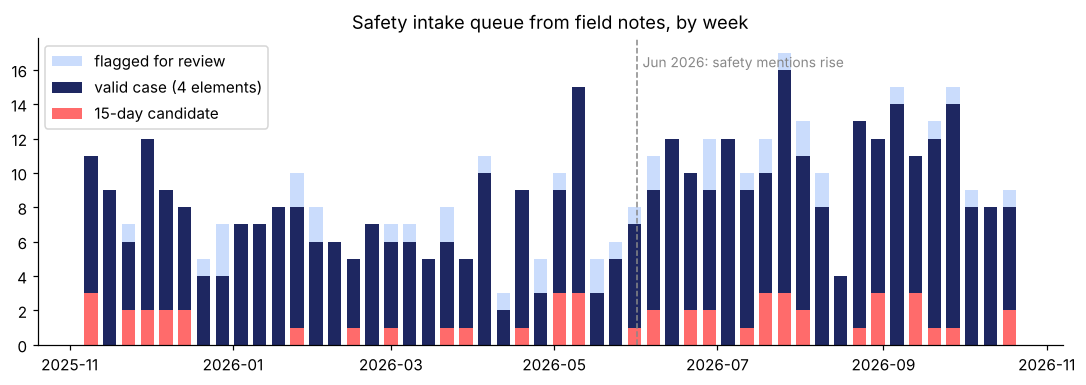

average 9 flags/week → about 0.9 reviewer-hours/week; 50 15-day candidates over the period


In [19]:
wk = q.set_index("call_date").resample("W").agg(flagged=("note_id", "size"), valid=("valid_case", "sum"), expedited=("expedited_15day", "sum"))
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(wk.index, wk.flagged, width=5, color=ICE, label="flagged for review"); ax.bar(wk.index, wk.valid, width=5, color=NAVY, label="valid case (4 elements)"); ax.bar(wk.index, wk.expedited, width=5, color=CORAL, label="15-day candidate")
ax.axvline(pd.Timestamp("2026-06-01"), color=GREY, ls="--", lw=1); ax.text(pd.Timestamp("2026-06-03"), wk.flagged.max() * 0.95, "Jun 2026: safety mentions rise", color=GREY, fontsize=9)
ax.set_title("Safety intake queue from field notes, by week"); ax.legend(loc="upper left"); save("intake_queue")
print(f"average {wk.flagged.mean():.0f} flags/week → about {wk.flagged.mean() * REVIEW_MIN / 60:.1f} reviewer-hours/week; {wk.expedited.sum()} 15-day candidates over the period")

What the queue is for: **reps are trained to report AEs within one business day**, but notes like these show the training does not catch everything. The detector is a safety net on the CRM, not a replacement for the SOP — and when a 15-day candidate surfaces the clock has *already been running* since the call date.

Two compliance side-effects worth a slide of their own:
* **PHI in free text.** A handful of notes contain a patient's name, DOB or MRN. Under HIPAA's Safe Harbor method (45 CFR 164.514(b)) these are among the 18 identifiers that must be removed before data can be treated as de-identified. Scrub before you store, and certainly before you send text to any external model.
* **Off-label mentions.** Unsolicited questions about unapproved uses are documented and routed to Medical Information; the rep must not engage. The same classifier family detects them (try it as an exercise).

## 7. What the field hears — topics, sentiment, competitor mentions

Same notes, a different question: not "is there an AE?" but "what are 60 reps hearing from 2,400 HCPs this month?". That is a **topic model**. We use NMF on TF-IDF (Lee & Seung, 1999) — fast, deterministic, and its topics are readable; LDA (Blei, Ng & Jordan, 2003) is the probabilistic classic and BERTopic (Grootendorst, 2022) the embedding-based modern option.

In [20]:
from sklearn.decomposition import NMF
STOP = set("the a an and or of to in for on with at by from is are was were be been has have had hcp dr office patient patients pt pts glucoren says said asked about will next this that it its as his her their they them not no".split())
DOMAIN_STOP = set("follow up visit week weeks two month next back also come holidays conversation minute staff friendly email sent scheduled left updated pi brief between good roughly sees t2d call bring data".split())   # rep boilerplate that carries no theme
def topic_prep(s):
    # concept normalization: every lexicon hit becomes one token, so 'threw up', 'N/V' and 'vomiting' count as the same thing
    s = re.sub(r"NOT_", "", normalize(s)); return LAY_RE.sub("aeterm", s)
tv = TfidfVectorizer(preprocessor=topic_prep, ngram_range=(1, 1), min_df=15, max_df=0.3, stop_words=list(STOP | DOMAIN_STOP), sublinear_tf=True)
Xt = tv.fit_transform(notes.note_text)
K = 8
nmf = NMF(n_components=K, init="nndsvda", random_state=7, max_iter=400).fit(Xt)
W = nmf.transform(Xt); terms = tv.get_feature_names_out()
top = {k: [terms[i] for i in nmf.components_[k].argsort()[::-1][:8]] for k in range(K)}
for k in range(K): print(f"topic {k}: " + ", ".join(top[k]))

topic 0: dose, whether, aeterm, insulin, reviewed, medical, information, doubled
topic 1: see, materials, rescheduled, all, clinic, did, day, closed
topic 2: hub, belief, reimbursement, paperwork, clinical, main, barrier, wants
topic 3: copay, more, card, samples, front, desk, program, obtained
topic 4: label, stayed, msl, cv, compares, how, yesterday, offered
topic 5: cardivex, but, cardiovascular, established, prefers, disease, tolerability, switched
topic 6: access, channel, system, digital, try, now, attempted, policy
topic 7: sub, group, renal, requested, analysis, starter, send, via


Topics are word clusters, not business themes: the model separates "copay card" from "prior auth" from "Medicare coverage gap" (all *access* to a brand lead) and blends safety mentions into dosing conversations. Two practical moves fix this: **roll topics up** into the themes the business uses, and **use the supervised detector for the theme you care most about** — we already have an AE detector, so safety is assigned by it, and the topic model organizes the rest.

{0: 'Dosing & combinations', 1: 'No-see / brief contact', 2: 'Access / payer', 3: 'Access / payer', 4: 'Education / MSL', 5: 'Competitor', 6: 'No-see / brief contact', 7: 'Samples / logistics'}


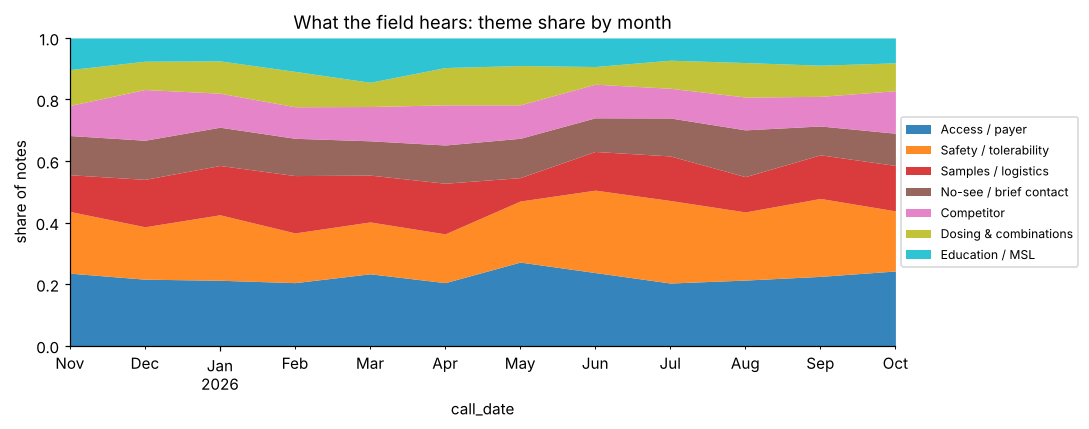

[instructor] agreement with the generator's 8 themes (adjusted mutual information): 0.31 raw topics · 0.38 rolled-up themes


In [21]:
def theme_of(words):
    w = " ".join(words)
    for name, keys in [("Competitor", ["cardivex"]), ("No-see / brief contact", ["see", "rescheduled", "hallway", "clinic", "unavailable", "channel", "policy"]),
                       ("Access / payer", ["pa", "copay", "assistance", "medicare", "reimbursement", "paperwork", "barrier", "hub", "tier", "formulary", "denials", "gap", "pharmacy"]),
                       ("Samples / logistics", ["samples", "materials", "receptionist", "training", "vouchers", "starter", "lunch", "signature"]),
                       ("Education / MSL", ["msl", "stayed", "label", "overview", "sub", "group", "renal", "requested", "reprint"]), ("Dosing & combinations", ["dose", "insulin", "titration", "food", "missed", "egfr"]),
                       ("Efficacy & everyday use", ["satisfied", "a1c", "glucose", "reductions", "extension", "durability", "metformin", "effect"])]:
        if any(k in w.split() for k in keys): return name
    return "Other"
NAMES = {k: theme_of(top[k]) for k in range(K)}; print(NAMES)
notes["topic_id"] = W.argmax(1)
notes["theme"] = np.where((notes.flag_ae == 1) | (notes.lex_flag == 1), "Safety / tolerability", notes.topic_id.map(NAMES))
share = notes.groupby([pd.Grouper(key="call_date", freq="MS"), "theme"]).size().unstack(fill_value=0); share = share.div(share.sum(1), axis=0)
order = share.mean().sort_values(ascending=False).index; share = share[order]
fig, ax = plt.subplots(figsize=(10, 4)); share.plot.area(ax=ax, colormap="tab10", alpha=.9, lw=0); ax.set_ylabel("share of notes"); ax.set_title("What the field hears: theme share by month"); ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=8); ax.set_ylim(0, 1)
save("topic_share")
if INSTR:
    from sklearn.metrics import adjusted_mutual_info_score
    print("[instructor] agreement with the generator's 8 themes (adjusted mutual information): %.2f raw topics · %.2f rolled-up themes" % (adjusted_mutual_info_score(notes_t.topic, notes.topic_id), adjusted_mutual_info_score(notes_t.topic, notes.theme)))

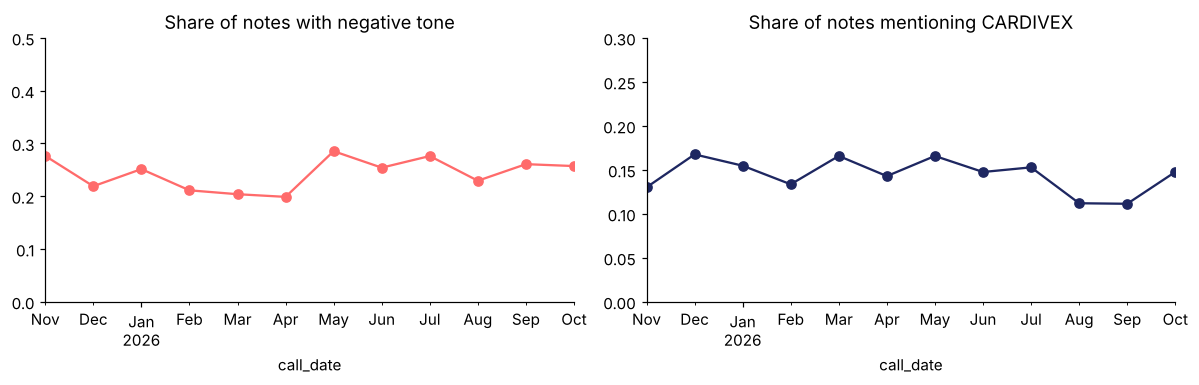

,notes,negative,ae_flag_rate
theme,,,
Access / payer,945,0.37,0.00
Safety / tolerability,874,0.34,0.52
Samples / logistics,586,0.04,0.00
No-see / brief contact,508,0.24,0.00
Competitor,476,0.30,0.00
Dosing & combinations,423,0.21,0.00
Education / MSL,388,0.01,0.00


In [22]:
# sentiment: a small lexicon (what the field says about us) — VADER-style word lists kept transparent on purpose
POS = set("satisfied pleased positive good better comfortable engaged receptive appreciated approved works improved excellent happy confident".split())
NEG = set("frustrated denied denials barrier skeptical concerned worried stopped switched pressure aggressive complaining unavailable hospitalized problem issue not".split())
def sent_score(s):
    w = re.findall(r"[a-z']+", normalize(s)); return (sum(x in POS for x in w) - sum(x in NEG for x in w)) / max(len(w), 1) * 10
notes["sent"] = notes.note_text.map(sent_score); notes["sent_label"] = pd.cut(notes.sent, [-99, -0.01, 0.01, 99], labels=["negative", "neutral", "positive"])
notes["mentions_competitor"] = notes.note_text.str.contains("CARDIVEX", case=False).astype(int)
m = notes.set_index("call_date").resample("MS").agg(negative_share=("sent_label", lambda s: (s == "negative").mean()), competitor_mentions=("mentions_competitor", "mean"))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
m.negative_share.plot(ax=ax[0], color=CORAL, marker="o"); ax[0].set_title("Share of notes with negative tone"); ax[0].set_ylim(0, 0.5)
m.competitor_mentions.plot(ax=ax[1], color=NAVY, marker="o"); ax[1].set_title("Share of notes mentioning CARDIVEX"); ax[1].set_ylim(0, 0.3)
save("sentiment_competitor")
notes.groupby("theme").agg(notes=("note_id", "size"), negative=("sent_label", lambda s: round((s == "negative").mean(), 2)), ae_flag_rate=("flag_ae", "mean")).sort_values("notes", ascending=False).round(2)

In [23]:
# the same cut by segment and specialty — the view a brand lead actually asks for
pd.crosstab(notes.hcp_segment, notes.theme, normalize="index").round(2).loc[["Grow", "Build", "Maintain", "Low priority"]]

theme,Access / payer,Competitor,Dosing & combinations,Education / MSL,No-see / brief contact,Safety / tolerability,Samples / logistics
hcp_segment,,,,,,,
Grow,0.24,0.12,0.09,0.09,0.12,0.19,0.15
Build,0.22,0.11,0.12,0.09,0.11,0.21,0.13
Maintain,0.22,0.11,0.10,0.09,0.12,0.22,0.14
Low priority,0.21,0.12,0.10,0.11,0.13,0.20,0.13


A topic model is a *reading aid*, not a truth machine: the names above are ours, the topics are mixtures, and a note about a patient who stopped for nausea *because* the payer moved the drug to tier 3 belongs to two themes at once. The value is the trend — the safety share rising from June, competitor mentions tracking CARDIVEX's label update — and the ability to drill from the chart to the notes behind it. (BERTopic, which clusters sentence embeddings instead of word counts, usually gives cleaner themes on short notes than NMF or LDA; the roll-up step is still yours.)

## 8. Social listening — the same detector on patient posts

Posts are first-person, lay language, emotional. A detector trained on rep notes ("HCP reports a patient developed…") has never seen "my stomach has been a mess since the dose went up". This is **domain shift**, and it is the single most common reason an NLP pilot that worked on one stream fails on the next.

Regulatory frame for this stream: FDA's 2001 draft guidance says applicants "should review any Internet sites sponsored by them for adverse experience information" and are not responsible for reviewing sites they do not sponsor; EMA's GVP Module VI says marketing-authorisation holders "should regularly screen internet or digital media under their management or responsibility". The company-sponsored community therefore carries an obligation; the independent forum carries awareness obligations only if someone looks. Deciding to *look* at the independent forum is a governance decision with consequences.

In [24]:
prev = posts[posts.pv_reviewed == 1].copy(); yp = prev.pv_label_ae.astype(int)
p_transfer = pipe.predict_proba(prev.text)[:, 1]
_ = report(yp, (p_transfer >= T_STAR).astype(int), "Notes-trained model → posts")
_ = report(yp, prev.text.map(lexicon_flag), "Lexicon → posts")
pipe_posts = make_pipeline(TfidfVectorizer(preprocessor=normalize, ngram_range=(1, 2), min_df=2, sublinear_tf=True), LogisticRegression(C=4.0, max_iter=2000, class_weight="balanced"))
pp_cv = cross_val_predict(pipe_posts, prev.text, yp, cv=cv, method="predict_proba")[:, 1]
_ = report(yp, (pp_cv >= 0.5).astype(int), "Posts-trained model (5-fold CV)")
# combined training set: notes + posts
both_X = pd.concat([rev.note_text, prev.text]); both_y = pd.concat([y, yp])
pipe_both = make_pipeline(TfidfVectorizer(preprocessor=normalize, ngram_range=(1, 2), min_df=2, sublinear_tf=True), LogisticRegression(C=4.0, max_iter=2000, class_weight="balanced")).fit(both_X, both_y)
_ = report(yp, (cross_val_predict(pipe_both, both_X, both_y, cv=cv, method="predict_proba")[:, 1][len(rev):] >= 0.5).astype(int), "Combined model, scored on posts")

Notes-trained model → posts        precision 0.64  recall 0.91  F1 0.75  flagged  282 of 741
Lexicon → posts                    precision 0.64  recall 0.85  F1 0.73  flagged  264 of 741
Posts-trained model (5-fold CV)    precision 0.94  recall 0.99  F1 0.97  flagged  209 of 741


Combined model, scored on posts    precision 0.94  recall 0.99  F1 0.97  flagged  209 of 741


In [25]:
pipe_posts.fit(prev.text, yp); posts["p_ae"] = pipe_posts.predict_proba(posts.text)[:, 1]; posts["flag_ae"] = (posts.p_ae >= 0.5).astype(int)
posts["serious_terms"] = posts.text.str.contains(SER_RE).astype(int)
summary = posts.groupby("source").agg(posts=("post_id", "size"), flagged=("flag_ae", "sum"), serious_terms=("serious_terms", lambda s: int((s * posts.loc[s.index, "flag_ae"]).sum())))
summary["obligation"] = ["screen regularly (under company management)" if "company" in i else "no screening duty; awareness duty if seen" for i in summary.index]
summary

,posts,flagged,serious_terms,obligation
source,,,,
Aspen 'Living with T2D' community (company-sponsored),1201,311,43,screen regularly (under company management)
T2D Circle forum (independent),1799,452,90,no screening duty; awareness duty if seen


The transfer result is the lesson: a model is only as good as the *distribution* it was trained on. Fix it with labels from the new stream (cheap here, expensive in practice), with a combined training set, or — the modern route — with pretrained embeddings that already know "threw up" and "vomiting" are neighbours (§11).

Golder, Norman & Loke's systematic review (2015) found that AEs reported in social media are more often mild and symptom-level, and under-represent serious events, compared with regulatory databases — which is exactly the mix in the forum above. Social listening finds *tolerability* signals and patient language; it is not where you find the pancreatitis case.

## 9. Medical-information routing — intent classification

The contact center asks a different question of the same toolbox: *what is this inquiry about, and where does it go?* Dosing and interaction questions go to the MI specialist; AE reports and product complaints go to Safety and Quality within the day; off-label and reimbursement questions have their own owners. IQVIA's MI paper describes exactly this: "automatic transfer of adverse events (AEs) and product complaints (PQCs) to their requisite systems".

In [26]:
from sklearn.metrics import classification_report
lab = mi[mi.mi_team_intent.notna()].copy(); unlab = mi[mi.mi_team_intent.isna()].copy()
pipe_mi = make_pipeline(TfidfVectorizer(preprocessor=normalize, ngram_range=(1, 2), min_df=2, sublinear_tf=True), LogisticRegression(C=6.0, max_iter=3000, class_weight="balanced"))
pred_cv = cross_val_predict(pipe_mi, lab.text, lab.mi_team_intent, cv=cv)
print(classification_report(lab.mi_team_intent, pred_cv, digits=2))
pipe_mi.fit(lab.text, lab.mi_team_intent); mi["intent_pred"] = pipe_mi.predict(mi.text)
# AEs hiding inside non-AE intents: run the AE detector over everything, not just the 'ae_report' queue
mi["ae_flag"] = ((pipe_both.predict_proba(mi.text)[:, 1] >= 0.5) | mi.text.str.contains(LAY_RE)).astype(int)
pd.crosstab(mi.intent_pred, mi.ae_flag, margins=True).rename(columns={0: "no AE words", 1: "AE flagged"})

                   precision    recall  f1-score   support

        ae_report       1.00      0.99      1.00       116
           dosing       0.93      0.92      0.93       121
          general       0.91      0.86      0.88        56
      interaction       0.87      0.91      0.89        74
        off_label       0.86      0.88      0.87        41
product_complaint       0.90      0.96      0.92        45
    reimbursement       0.91      0.90      0.91        90
          storage       0.88      0.88      0.88        42

         accuracy                           0.92       585
        macro avg       0.91      0.91      0.91       585
     weighted avg       0.92      0.92      0.92       585



ae_flag,no AE words,AE flagged,All
intent_pred,,,
ae_report,0,222,222
dosing,193,60,253
general,115,0,115
interaction,119,35,154
off_label,87,0,87
product_complaint,80,15,95
reimbursement,177,0,177
storage,96,1,97
All,867,333,1200


The cross-tab is the operational point: a meaningful number of AE mentions arrive inside *dosing* and *interaction* calls ("…asks about the dose because the patient has had nausea since starting"). Routing by intent alone would send them to the wrong queue. Run the safety detector on every record, whatever its intent.

## 10. Signal detection — from cases to a signal

Once cases are in the safety database the question changes from "is this an AE?" to "is this event reported with our drug *more often than expected*?" The workhorse is **disproportionality analysis** on spontaneous-report databases such as FDA's FAERS: the Proportional Reporting Ratio (Evans, Waller & Davis, 2001) and the Reporting Odds Ratio, with Bayesian shrinkage variants (Bate et al., 1998; DuMouchel, 1999) for sparse cells.

Evans's screening rule: **PRR ≥ 2, χ² ≥ 4, and at least 3 cases**. The table below is *synthetic*, shaped like a FAERS extract: for each event, reports with GLUCOREN and reports with all other drugs.

In [27]:
fa = pd.read_csv(DATA / "faers_style_counts_glucoren.csv")
a = fa.glucoren_reports_with_event; b = fa.glucoren_reports_total - a; c = fa.other_drugs_reports_with_event; d = fa.other_drugs_reports_total - c
fa["PRR"] = (a / (a + b)) / (c / (c + d))
fa["ROR"] = (a * d) / (b * c)
se_lnror = np.sqrt(1 / a + 1 / b + 1 / c + 1 / d); fa["ROR_lo"], fa["ROR_hi"] = np.exp(np.log(fa.ROR) - 1.96 * se_lnror), np.exp(np.log(fa.ROR) + 1.96 * se_lnror)
n = a + b + c + d; E = (a + b) * (a + c) / n; fa["chi2"] = (a - E) ** 2 / E + (b - ((a + b) * (b + d) / n)) ** 2 / ((a + b) * (b + d) / n) + (c - ((c + d) * (a + c) / n)) ** 2 / ((c + d) * (a + c) / n) + (d - ((c + d) * (b + d) / n)) ** 2 / ((c + d) * (b + d) / n)
fa["signal_evans"] = (fa.PRR >= 2) & (fa.chi2 >= 4) & (a >= 3)
fa["in_label"] = fa.event_pt.map(dict(zip(lex.course_pt, lex.in_label))).fillna("?")
show = fa.sort_values("PRR", ascending=False)[["event_pt", "glucoren_reports_with_event", "PRR", "ROR", "ROR_lo", "ROR_hi", "chi2", "signal_evans", "in_label"]].round(2)
show.head(12)

,event_pt,glucoren_reports_with_event,PRR,ROR,ROR_lo,ROR_hi,chi2,signal_evans,in_label
14,Pancreatitis,55,3.59,3.61,2.77,4.72,102.64,True,N
5,Hypoglycaemia,219,2.94,3.01,2.63,3.44,282.20,True,Y
0,Nausea,595,2.40,2.55,2.34,2.77,505.14,True,Y
9,Decreased appetite,120,1.94,1.95,1.63,2.34,54.73,False,Y
1,Diarrhoea,350,1.89,1.94,1.74,2.16,150.03,False,Y
11,Dehydration,82,1.66,1.66,1.34,2.07,21.40,False,Y
6,Urinary tract infection,134,1.44,1.45,1.22,1.72,18.37,False,Y
10,Weight decreased,101,1.36,1.37,1.12,1.67,9.83,False,Y
15,Acute kidney injury,64,1.14,1.14,0.89,1.46,1.14,False,N
7,Rash,199,1.07,1.07,0.93,1.24,0.96,False,Y


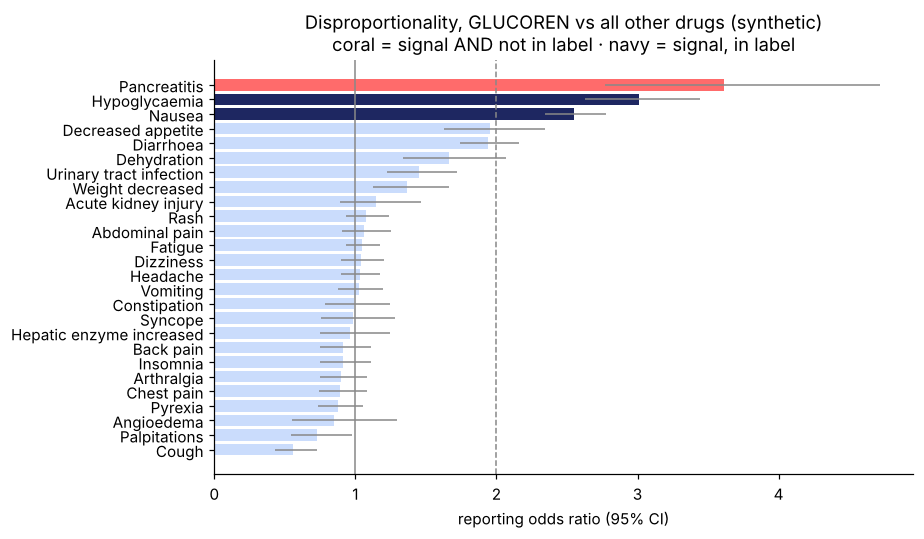

[instructor] planted relative rates ≥ 1.5: {'Nausea': 2.2, 'Diarrhoea': 1.9, 'Hypoglycaemia': 2.6, 'Urinary tract infection': 1.7, 'Decreased appetite': 1.8, 'Weight decreased': 1.6, 'Dehydration': 1.5, 'Pancreatitis': 3.4}


In [28]:
fig, ax = plt.subplots(figsize=(8.5, 5))
s = fa.sort_values("ROR"); colors = [CORAL if (sig and lab == "N") else (NAVY if sig else ICE) for sig, lab in zip(s.signal_evans, s.in_label)]
ax.barh(s.event_pt, s.ROR, color=colors); ax.errorbar(s.ROR, s.event_pt, xerr=[s.ROR - s.ROR_lo, s.ROR_hi - s.ROR], fmt="none", ecolor=GREY, lw=1)
ax.axvline(1, color=GREY, lw=1); ax.axvline(2, color=GREY, ls="--", lw=1); ax.set_xlabel("reporting odds ratio (95% CI)"); ax.set_title("Disproportionality, GLUCOREN vs all other drugs (synthetic)\ncoral = signal AND not in label · navy = signal, in label")
save("disproportionality")
if INSTR:
    st = pd.read_csv(INSTR / "_INSTRUCTOR_faers_signal_truth.csv"); print("[instructor] planted relative rates ≥ 1.5:", st[st.true_relative_rate >= 1.5].set_index("event_pt").true_relative_rate.to_dict())

Pancreatitis stands out: a signal by Evans's rule and **not in the label** — the kind of finding that goes to a signal-review committee, not to a dashboard. Everything about this step is *statistics on counts*; what NLP contributes upstream is getting the cases into the counts at all. Reporting rates are not incidence rates (there is no denominator of exposed patients, and under-reporting is severe — Hazell & Shakir's 2006 review put the median under-reporting rate of ADRs at 94%), so disproportionality raises hypotheses; it does not test them.

## 11. Semantic search — LSA as a stand-in for embeddings

Modern NLP represents text as dense vectors in which "threw up" sits next to "vomiting". Tonight we use **Latent Semantic Analysis** (truncated SVD on the TF-IDF matrix; Deerwester et al., 1990) because it runs offline in a second and shows the mechanics. In practice you would swap in **sentence-transformers** (Reimers & Gurevych, 2019) or a provider embedding API — same code shape, better neighbours. A domain model (**BioBERT**, Lee et al., 2020; **ClinicalBERT**, Alsentzer et al., 2019; **PubMedBERT**, Gu et al., 2021) helps when the vocabulary is clinical; for rep notes and patient posts a general model is usually good enough — test before you pay for the domain one.

In [29]:
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize as l2
svd = TruncatedSVD(n_components=120, random_state=7)
Z = l2(svd.fit_transform(Xt))
def search(query, k=5):
    qz = l2(svd.transform(tv.transform([query]))); sims = Z @ qz.T
    idx = np.argsort(-sims.ravel())[:k]
    return pd.DataFrame({"similarity": sims.ravel()[idx].round(3), "note": notes.note_text.iloc[idx].values})
for qtext in ["patient stopped the drug because of stomach problems", "payer requires prior authorization, patients waiting", "competitor has better heart data"]:
    print("\nQUERY:", qtext); display(search(qtext))


QUERY: patient stopped the drug because of stomach problems


,similarity,note
0,0.659,"A 73 y/o m stopped GLUCOREN because of palpitations, moderate. HCP switched to CARDIVEX. Also reviewed the copay program."
1,0.615,"Per the MA, one of his patients returned the bottle after yeast infection. HCP not sure it was the drug but has stopped it."
2,0.605,"Per the MA, Mr. Kim, MRN 319912 returned the bottle after nausea, persistent. HCP not sure it was the drug but has stopped it. Good 10-minute conversation."
3,0.598,"Per the MA, Mr. Hernandez, MRN 950829 returned the bottle after rash, significant. HCP not sure it was the drug but has stopped it. Will follow up next month."
4,0.598,A 78yo male with nafld stopped GLUCOREN because of heart racing after starting GLUCOREN. HCP switched to CARDIVEX. Office staff friendly as always.



QUERY: payer requires prior authorization, patients waiting


,similarity,note
0,0.727,Dr. reports Humana is requiring prior authorization for GLUCOREN; two pts waiting over a week. Left PA form and hub phone number.
1,0.727,Dr. reports Humana is requiring prior authorization for GLUCOREN; two pts waiting over a week. Left PA form & hub phone number. HCP sees roughly 34 T2D pts ...
2,0.727,Dr. reports Humana is requiring prior authorization for GLUCOREN; two patients waiting over a week. Left PA form and hub phone number. Scheduled a follow-up...
3,0.722,Dr. reports Cigna is requiring prior authorization for GLUCOREN; two patients waiting over a week. Left PA form and hub phone number. Left the updated PI.
4,0.722,Dr. reports Cigna is requiring prior authorization for GLUCOREN; two patients waiting over a week. Left PA form and hub phone number. Will follow up next mo...



QUERY: competitor has better heart data


,similarity,note
0,0.737,No rash complaints so far in about 16 patients. HCP says GLUCOREN is one of the better-tolerated add-ons.
1,0.737,No dizziness complaints so far in about 35 patients. HCP says GLUCOREN is one of the better-tolerated add-ons.
2,0.737,No yeast infection complaints so far in about 34 pts. HCP says GLUCOREN is one of the better-tolerated add-ons.
3,0.737,No exhausted complaints so far in about 15 patients. HCP says GLUCOREN is one of the better-tolerated add-ons. Left the updated PI.
4,0.716,No palpitations complaints so far in about 26 patients. HCP says GLUCOREN is one of the better-tolerated add-ons.


In [30]:
# the same search with a real sentence embedding model (set to True on a machine with internet access and `pip install sentence-transformers`)
USE_TRANSFORMERS = False
if USE_TRANSFORMERS:
    from sentence_transformers import SentenceTransformer
    st_model = SentenceTransformer("all-MiniLM-L6-v2")            # general-purpose; try "pritamdeka/S-BioBert-snli-multinli-stsb" for a biomedical one
    E = l2(st_model.encode(notes.note_text.tolist(), batch_size=64, show_progress_bar=False))
    qe = l2(st_model.encode(["patient stopped the drug because of stomach problems"]))
    idx = np.argsort(-(E @ qe.T).ravel())[:5]; display(notes.note_text.iloc[idx])
    # and a fine-tuned AE classifier is ~10 lines with transformers' Trainer on (rev.note_text, y) — see the Field Guide, §7
else:
    print("Transformer cells are switched off (no model download in class). The LSA search above shows the mechanics; the Field Guide lists the swap-in code.")

Transformer cells are switched off (no model download in class). The LSA search above shows the mechanics; the Field Guide lists the swap-in code.


## 12. Where GenAI fits — a preview (full session later in the term)

Large language models change the *economics* of this pipeline, not its *logic*:

* **Zero-shot extraction.** A prompt can return `{ "ae_mentioned": true, "event": "nausea", "patient": "61-year-old female", "serious": false }` from a note with no training set — useful for the long tail of events a lexicon never listed, and for the four-element check.
* **Normalization and narrative.** Mapping lay terms to a coding dictionary, drafting the case narrative, summarizing a week of field notes for the brand lead.
* **What does not change.** The four elements, the seriousness criteria, the 15-day clock, human review of every case, PHI handling before any text leaves the firewall, and the need to *measure* recall on your own labelled data. IQVIA reports that across industries "more than 70% of GenAI experiments fail to make it to production"; the ones that survive are evaluated like the models above — precision, recall, workload — not demoed.

```text
SYSTEM: You are a pharmacovigilance intake assistant. Do not infer facts not present in the note.
USER:   Note: "{note_text}"
        Return JSON with keys: ae_mentioned (bool), events (list of lay terms as written), identifiable_patient (bool, with the
        phrase that identifies them), reporter (string), suspect_drug (string), seriousness_terms (list), evidence (verbatim spans).
```

Everything in that prompt maps to a column we computed tonight — which is how you will evaluate it.

In [31]:
# instructor only: write the key numbers the deck and handouts quote (single source of truth for the build scripts)
if INSTR:
    key = dict(n_notes=int(len(notes)), n_posts=int(len(posts)), n_mi=int(len(mi)), n_lex=int(len(lex)), n_pt=int(lex.course_pt.nunique()), reviewed_notes=int(rev.shape[0]), reviewed_posts=int(prev.shape[0]), mi_labelled=int(lab.shape[0]),
               lex_precision=float(precision_score(y, rev.lex_flag)), lex_recall=float(recall_score(y, rev.lex_flag)), lex_flagged=int(rev.lex_flag.sum()),
               lr_auc=float(roc_auc_score(y, proba_cv)), lr_ap=float(average_precision_score(y, proba_cv)), lr_p50=float(precision_score(y, (proba_cv >= 0.5).astype(int))), lr_r50=float(recall_score(y, (proba_cv >= 0.5).astype(int))),
               t_star=T_STAR, lr_p_star=float(precision_score(y, flag_star)), lr_r_star=float(recall_score(y, flag_star)), flagged_star=int(flag_star.sum()), vocab=int(len(vec.vocabulary_)),
               stream_flagged=int(notes.flag_ae.sum()), unrev_recall=float(recall_score(unrev.ae_present, unrev.flag_ae)), unrev_precision=float(precision_score(unrev.ae_present, unrev.flag_ae)), unrev_lex_recall=float(recall_score(unrev.ae_present, unrev.lex_flag)),
               q_flagged=int(len(q)), q_valid=int(q.valid_case.sum()), q_serious=int(q.serious_terms.sum()), q_15day=int(q.expedited_15day.sum()), q_phi=int(q.phi_in_note.sum()), true_15day=int(truth.expedited_15day.sum()), flags_per_week=float(wk.flagged.mean()), hours_per_week=float(wk.flagged.mean() * REVIEW_MIN / 60),
               probe=[(t, float(pipe.predict_proba([t])[0, 1])) for t in probe], cost_table=rows, leaks=leaks[:6],
               transfer_p=float(precision_score(yp, (p_transfer >= T_STAR).astype(int))), transfer_r=float(recall_score(yp, (p_transfer >= T_STAR).astype(int))), posts_lex_p=float(precision_score(yp, prev.text.map(lexicon_flag))), posts_lex_r=float(recall_score(yp, prev.text.map(lexicon_flag))),
               posts_cv_p=float(precision_score(yp, (pp_cv >= 0.5).astype(int))), posts_cv_r=float(recall_score(yp, (pp_cv >= 0.5).astype(int))), posts_summary=summary.reset_index().to_dict("records"),
               mi_accuracy=float((pred_cv == lab.mi_team_intent).mean()), mi_ae_in_other=int(mi[(mi.intent_pred != "ae_report") & (mi.ae_flag == 1)].shape[0]), mi_ae_total=int(mi.ae_flag.sum()),
               signals=show[show.signal_evans].event_pt.tolist(), prr=show.set_index("event_pt").PRR.round(2).to_dict(), topics={int(k): v for k, v in NAMES.items()}, top_words={int(k): v for k, v in top.items()},
               theme_table=notes.groupby("theme").agg(notes=("note_id", "size"), negative=("sent_label", lambda s: round((s == "negative").mean(), 2)), ae_flag_rate=("flag_ae", "mean")).round(2).reset_index().to_dict("records"),
               safety_share_before=float((notes[notes.call_date < "2026-06-01"].theme == "Safety / tolerability").mean()), safety_share_after=float((notes[notes.call_date >= "2026-06-01"].theme == "Safety / tolerability").mean()),
               coef_top=content.tail(12)[::-1].round(2).to_dict(), coef_bottom=content.head(12).round(2).to_dict(),
               highlight=[dict(note_id=r.note_id, p=float(r.p_ae), flag=int(r.flag_ae), lex=int(r.lex_flag), words=[(w, float(contributions(r.note_text)[0].get(re.sub(r"[^a-z0-9/]", "", nw), 0.0))) for w, nw in zip(r.note_text.split(), normalize(r.note_text).split())]) for _, r in examples.iterrows()],
               lime_example=dict(text=ex.note_text, p=float(p0), weights=pd.concat([lime.tail(5)[::-1], lime.head(4)]).round(3).to_dict()))
    json.dump(key, open(INSTR / "build" / "key_numbers.json", "w"), indent=1, default=str); print("key_numbers.json written")

key_numbers.json written


## Wrap-up — the checklist a PV lead will hold you to

1. **Define the target in regulatory terms** before modelling (four elements, serious, unexpected, the clock).
2. **Start with a lexicon** to learn the failure modes; **move to a learned model** for negation, paraphrase and abbreviations.
3. **Choose the threshold on recall and workload**, not on F1. Write the cost table down.
4. **Explain every flag** in the reviewer's language — the highlighted span. Keep behavioural probes under version control.
5. **Rules after the model**: identifiable patient, seriousness terms, due date, PHI scrub.
6. **Expect domain shift** on every new stream; get labels there first.
7. **Signals are statistics on counts**; NLP's job is to get the cases into the counts.
8. **Document the model in the PV system master file** (model, data, metrics, controls, human oversight) — governance is part of the deliverable.

*Next: Week 8 — academic holiday (Homework 2 due Mon Nov 2, 11:59 PM ET). Week 9 — midterm; the study guide covers Weeks 1–7.*